In [6]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import LabelEncoder
import wandb
import warnings
warnings.filterwarnings('ignore')

## W&B Initialization

In [8]:
wandb.init(
    project="DL-23f1000967-notebook-t22026",
    name="EDA_tfidf_baseline",
    config={
        "method": "EDA + TF-IDF + Cosine Similarity",
        "description": "Baseline model using TF-IDF embeddings"
    }
)

wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice:

  2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.
wandb: Paste your API key and hit enter:

  ········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: 23f1000967 (23f1000967-indian-institute-of-technology-madras) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


## load Data

In [9]:
train = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv')
test = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv')
sample_sub = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv')

print(f"Train shape: {train.shape}")
print(f"Test shape: {test.shape}")
print(f"\nTrain columns: {train.columns.tolist()}")
print(f"\nSample train row:")
print(train.iloc[0])

Train shape: (2000, 8)
Test shape: (500, 7)

Train columns: ['id', 'prompt', 'A', 'B', 'C', 'D', 'E', 'answer']

Sample train row:
id                                                        1
prompt    Pick the best possible answer: What is Martin ...
A         Martin Heidegger believes that humans exist wi...
B         Martin Heidegger believes that humans do not e...
C         Martin Heidegger does not believe in the exist...
D         Martin Heidegger believes that the relationshi...
E         Martin Heidegger believes that time is an illu...
answer                                                    B
Name: 0, dtype: object


## EXPLORATORY DATA ANALYSIS

In [10]:
# Answer distribution
answer_counts = train['answer'].value_counts().sort_index()
print("\nAnswer Distribution:")
print(answer_counts)


Answer Distribution:
answer
A    369
B    490
C    459
D    358
E    324
Name: count, dtype: int64


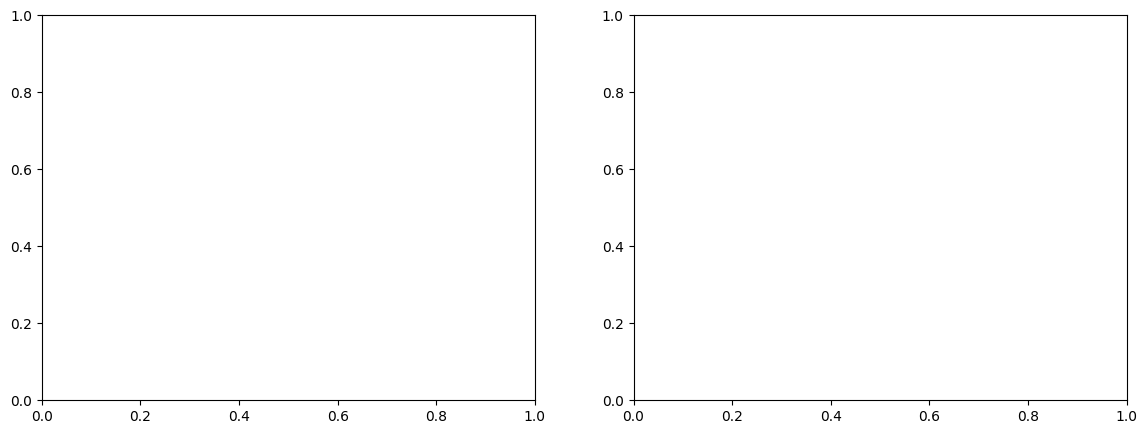

In [11]:
# Plot answer distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

In [12]:
# Bar plot
axes[0].bar(answer_counts.index, answer_counts.values, color=['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7'])
axes[0].set_xlabel('Answer Label')
axes[0].set_ylabel('Count')
axes[0].set_title('Distribution of Answers in Training Data')
axes[0].set_xticks(['A', 'B', 'C', 'D', 'E'])

In [13]:
# Pie chart
axes[1].pie(answer_counts.values, labels=answer_counts.index, autopct='%1.1f%%', 
           colors=['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7'])
axes[1].set_title('Answer Distribution (Percentage)')

plt.tight_layout()
plt.savefig('answer_distribution.png', dpi=150, bbox_inches='tight')
wandb.log({"answer_distribution": wandb.Image('answer_distribution.png')})
plt.show()

<Figure size 640x480 with 0 Axes>

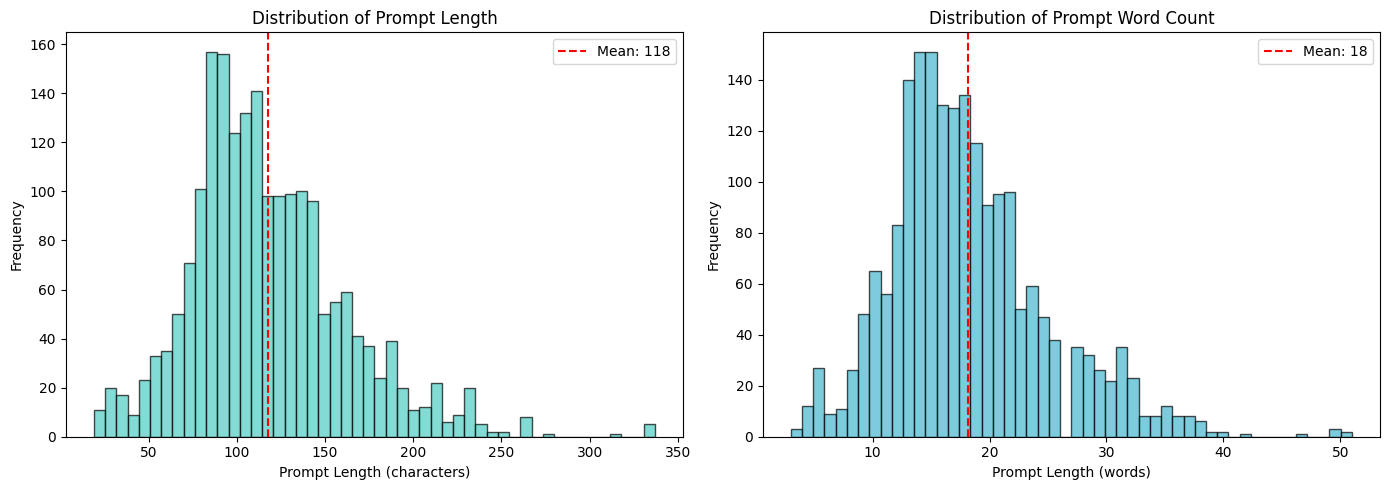

In [14]:
# Text length analysis
train['prompt_length'] = train['prompt'].str.len()
train['prompt_words'] = train['prompt'].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(train['prompt_length'], bins=50, color='#4ECDC4', edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Prompt Length (characters)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Distribution of Prompt Length')
axes[0].axvline(train['prompt_length'].mean(), color='red', linestyle='--', label=f'Mean: {train["prompt_length"].mean():.0f}')
axes[0].legend()

axes[1].hist(train['prompt_words'], bins=50, color='#45B7D1', edgecolor='black', alpha=0.7)
axes[1].set_xlabel('Prompt Length (words)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Distribution of Prompt Word Count')
axes[1].axvline(train['prompt_words'].mean(), color='red', linestyle='--', label=f'Mean: {train["prompt_words"].mean():.0f}')
axes[1].legend()

plt.tight_layout()
plt.savefig('prompt_length_analysis.png', dpi=150, bbox_inches='tight')
wandb.log({"prompt_length_analysis": wandb.Image('prompt_length_analysis.png')})
plt.show()

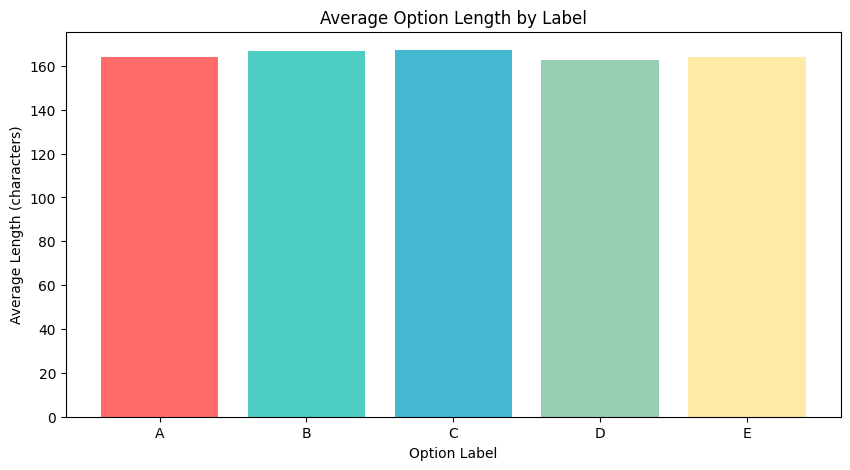

In [15]:
# Option length analysis
for opt in ['A', 'B', 'C', 'D', 'E']:
    train[f'{opt}_length'] = train[opt].str.len()

option_lengths = [train[f'{opt}_length'].mean() for opt in ['A', 'B', 'C', 'D', 'E']]

plt.figure(figsize=(10, 5))
plt.bar(['A', 'B', 'C', 'D', 'E'], option_lengths, color=['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7'])
plt.xlabel('Option Label')
plt.ylabel('Average Length (characters)')
plt.title('Average Option Length by Label')
plt.savefig('option_length_analysis.png', dpi=150, bbox_inches='tight')
wandb.log({"option_length_analysis": wandb.Image('option_length_analysis.png')})
plt.show()

In [16]:
# Log EDA stats to W&B
wandb.log({
    "train_size": len(train),
    "test_size": len(test),
    "avg_prompt_length": train['prompt_length'].mean(),
    "avg_prompt_words": train['prompt_words'].mean(),
    "min_prompt_length": train['prompt_length'].min(),
    "max_prompt_length": train['prompt_length'].max()
})

## Text Cleaning

In [17]:
import re

def clean_text(text):
    """Clean and preprocess text data"""
    if pd.isna(text):
        return ""
    # Convert to lowercase
    text = str(text).lower()
    
    # Remove special characters but keep spaces
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    
    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()
    return text

In [18]:
# Apply cleaning
for col in ['prompt', 'A', 'B', 'C', 'D', 'E']:
    train[f'{col}_clean'] = train[col].apply(clean_text)
    test[f'{col}_clean'] = test[col].apply(clean_text)

print("Text cleaning completed!")
print(f"\nSample cleaned prompt: {train['prompt_clean'].iloc[0][:200]}...")

Text cleaning completed!

Sample cleaned prompt: pick the best possible answer what is martin heidegger s view on the relationship between time and human existence among the listed options...


## TF-IDF Vectorization

In [19]:
# Combine prompt and each option for TF-IDF
def create_combined_text(row, option):
    """Combine prompt with option for TF-IDF"""
    return f"{row['prompt_clean']} {row[f'{option}_clean']}"

In [20]:
# Create TF-IDF vectorizer
# from sklearn.feature_extraction.text import (
#     TfidfVectorizer,
#     ENGLISH_STOP_WORDS
# )
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    stop_words='english'
)

In [21]:
# Fit on all text data
all_texts = []
for opt in ['A', 'B', 'C', 'D', 'E']:
    all_texts.extend(train[f'{opt}_clean'].tolist())
    all_texts.extend(test[f'{opt}_clean'].tolist())
all_texts.extend(train['prompt_clean'].tolist())
all_texts.extend(test['prompt_clean'].tolist())

tfidf.fit(all_texts)
print(f"TF-IDF vocabulary size: {len(tfidf.vocabulary_)}")

TF-IDF vocabulary size: 5000
